<a href="https://colab.research.google.com/github/iswaryasekar5/CSA4708-DEEP-LEARNING/blob/main/CSA4708_DEEP_LEARNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
print("Addition:", a + b)
print("Dot Product:", np.dot(a, b))
print("Matrix:\n", np.array([[1, 2], [3, 4]]))

Addition: [5 7 9]
Dot Product: 32
Matrix:
 [[1 2]
 [3 4]]


In [2]:
import numpy as np
a = np.array([[1, 2], [3, 4], [5, 6]])
print("Covariance:\n", np.cov(a.T))
v, w = np.linalg.eig(np.cov(a.T))
print("Eigenvalues:", v)
print("Eigenvectors:\n", w)

Covariance:
 [[4. 4.]
 [4. 4.]]
Eigenvalues: [8. 0.]
Eigenvectors:
 [[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [3]:
from scipy.stats import norm, binom
print("Normal PDF:", norm.pdf(0))
print("Binomial Probability:", binom.pmf(2, 5, 0.5))
p_a, p_b_given_a, p_b = 0.4, 0.8, 0.5
print("Bayes' Theorem:", p_b_given_a * p_a / p_b)

Normal PDF: 0.3989422804014327
Binomial Probability: 0.31249999999999983
Bayes' Theorem: 0.6400000000000001


In [4]:
import numpy as np
from scipy.stats import entropy
p = [0.5, 0.5]
q = [0.8, 0.2]
print("Entropy:", entropy(p))
print("Cross-Entropy:", -np.sum(np.array(p) * np.log(q)))
print("KL Divergence:", entropy(p, q))

Entropy: 0.6931471805599453
Cross-Entropy: 0.916290731874155
KL Divergence: 0.22314355131420974


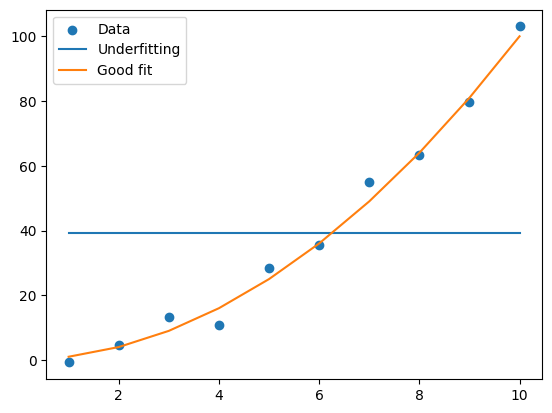

In [5]:
import numpy as np
import matplotlib.pyplot as plt
x = np.arange(1, 11)
y = x**2 + np.random.randn(10)*2
plt.scatter(x, y)
plt.plot(x, x*0+np.mean(y))
plt.plot(x, x**2)
plt.legend(["Data", "Underfitting", "Good fit"])
plt.show()

In [6]:
import tensorflow as tf
for name in ["SGD", "Momentum", "Adam"]:
    opt = {"SGD": tf.keras.optimizers.SGD(),
           "Momentum": tf.keras.optimizers.SGD(momentum=0.9),
           "Adam": tf.keras.optimizers.Adam()}[name]
    x = tf.Variable(0.0)
    for _ in range(100):
        with tf.GradientTape() as t:
            loss = (x - 5)**2
        opt.apply_gradients([(t.gradient(loss, x), x)])
    print(name, "Result:", x.numpy())

SGD Result: 4.3369026
Momentum Result: 4.97886
Adam Result: 0.0996592


In [7]:
import numpy as np
x = np.array([1, 0])
w = np.array([0.5, 0.3])
b = 0.2
print("Output:", int(np.dot(x, w) + b > 0))

Output: 1


In [8]:
import numpy as np
x = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])
model = __import__('tensorflow').keras.Sequential([
    __import__('tensorflow').keras.layers.Dense(4, activation='relu'),
    __import__('tensorflow').keras.layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam', loss='binary_crossentropy')
model.fit(x, y, epochs=500, verbose=0)
print(np.round(model.predict(x, verbose=0)))

[[0.]
 [1.]
 [0.]
 [0.]]


In [9]:
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
x, y = load_iris(return_X_y=True)
a, b, c, d = train_test_split(x, y, test_size=0.2, random_state=42)
m = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])
m.compile(optimizer='adam', loss='sparse_categorical_crossentropy',
          metrics=['accuracy'])
m.fit(a, c, epochs=20, verbose=0)
print("Accuracy:", m.evaluate(b, d, verbose=0)[1])

Accuracy: 0.30000001192092896


In [11]:
import tensorflow as tf
m = tf.keras.Sequential([
    tf.keras.layers.Dense(8, activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(0.01)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
m.compile(optimizer='adam', loss='binary_crossentropy')
x = tf.random.normal((20, 10))
y = tf.cast(tf.reduce_sum(x, axis=1) > 0, tf.float32)
m.fit(x, y, epochs=5, verbose=0,
      callbacks=[tf.keras.callbacks.EarlyStopping(patience=1)])
print("Completed")

Completed


In [13]:
import tensorflow as tf
(x, y), _ = tf.keras.datasets.mnist.load_data()
x = x[:500].reshape(500, 28, 28, 1) / 255.0
y = y[:500]
m = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(8, (3, 3), activation='relu'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(10, activation='softmax')
])
m.compile(optimizer='adam',
          loss='sparse_categorical_crossentropy',
          metrics=['accuracy'])
m.fit(x, y, epochs=2, verbose=1)
print("CNN Image Classification Completed")

Epoch 1/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - accuracy: 0.4980 - loss: 1.9281
Epoch 2/2
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.8180 - loss: 1.0708
CNN Image Classification Completed


In [14]:
import tensorflow as tf
(x, y), _ = tf.keras.datasets.mnist.load_data()
x = x[:500].reshape(500, 28, 28, 1) / 255.0
y = y[:500]
for f in [8, 16]:
    m = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(f, (3, 3), activation='relu'),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    m.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
    m.fit(x, y, epochs=1, verbose=0)
    print("Filters:", f, "Parameters:", m.count_params())

Filters: 8 Parameters: 54170
Filters: 16 Parameters: 108330
